# 实验三 A：基于 Grad-CAM 的模型可视化

使用 ImageNet 预训练 ResNet-18，对金鱼、金毛犬、虎斑猫、客机和校车五类图片进行预测和 Grad-CAM 可视化。每组展示原图、热力图和叠加图，图片和结果保存在本地，首次运行需要联网下载约 45 MB 的模型权重。

图片来源：[ImageNet sample images](https://github.com/EliSchwartz/imagenet-sample-images)。这里只做五张图片的可视化，不用它们估计模型在整个数据集上的准确率。

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights

ROOT = Path.cwd()
if ROOT.name != "exp3" and (ROOT / "exp3").is_dir():
    ROOT = ROOT / "exp3"
DATA_DIR = ROOT / "data" / "gradcam_samples"
RESULT_DIR = ROOT / "results" / "exp3A"
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(ROOT / ".cache" / "torch"))

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("运行设备：", device)

运行设备： cpu


## 1. 加载模型和图片

ResNet-18 由初始卷积、四组残差模块、全局平均池化和全连接分类层组成，输出 ImageNet 的 1000 个类别。使用预训练权重自带的预处理：短边缩放至 256、中心裁剪至 224 × 224，再标准化。可视化中的原图使用同一裁剪区域，使热力图与图像位置对应。

In [2]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()
preprocess = weights.transforms()
class_names = weights.meta["categories"]
target_layer = model.layer4[-1]

print(model)
print("Grad-CAM 目标层：layer4[-1]，输出形状为 [1, 512, 7, 7]")
print("模型参数量：", sum(p.numel() for p in model.parameters()))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to E:\CODE\DeepLearning-exp\exp3\.cache\torch\checkpoints\resnet18-f37072fd.pth


  0%|          | 0.00/44.7M [00:00<?, ?B/s]

  1%|▏         | 640k/44.7M [00:00<00:07, 6.19MB/s]

  4%|▍         | 1.88M/44.7M [00:00<00:04, 9.40MB/s]

  6%|▋         | 2.88M/44.7M [00:00<00:04, 9.82MB/s]

...

 93%|█████████▎| 41.8M/44.7M [00:04<00:00, 8.34MB/s]

 95%|█████████▌| 42.6M/44.7M [00:04<00:00, 8.39MB/s]

 97%|█████████▋| 43.5M/44.7M [00:04<00:00, 8.45MB/s]

100%|██████████| 44.7M/44.7M [00:04<00:00, 9.97MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [3]:
samples = [
    ("goldfish", "n01443537_goldfish.JPEG"),
    ("golden retriever", "n02099601_golden_retriever.JPEG"),
    ("tabby", "n02123045_tabby.JPEG"),
    ("airliner", "n02690373_airliner.JPEG"),
    ("school bus", "n04146614_school_bus.JPEG"),
]
base_url = "https://raw.githubusercontent.com/EliSchwartz/imagenet-sample-images/master/"

for label, filename in samples:
    path = DATA_DIR / filename
    if not path.exists():
        urlretrieve(base_url + filename, path)
    with Image.open(path) as image:
        print(f"{label:18s} 原始尺寸：{image.size}")

goldfish           原始尺寸：(376, 263)


golden retriever   原始尺寸：(300, 500)


tabby              原始尺寸：(335, 500)


airliner           原始尺寸：(500, 332)


school bus         原始尺寸：(500, 334)


## 2. 实现 Grad-CAM

目标层选择最后一组残差模块的输出 `layer4[-1]`。前向传播保存特征图 $A$，以预测类别的未归一化分数 $y^c$ 反向传播，获取其对特征图的梯度。通道权重是梯度在空间维度的平均值：

$$\alpha_k^c = \frac{1}{HW}\sum_i\sum_j\frac{\partial y^c}{\partial A_{ij}^k}$$

对特征图加权求和，经过 ReLU 保留正向贡献，再上采样到输入大小并归一化：

$$L^c = \mathrm{ReLU}\left(\sum_k \alpha_k^c A^k\right)$$

这里直接使用 PyTorch 的 hook 和自动求导，不额外安装 Grad-CAM 库。

In [4]:
def grad_cam(input_tensor, target_class=None):
    features = {}

    def save_features(module, inputs, output):
        features["activation"] = output
        output.retain_grad()  # 保存非叶子张量的梯度

    handle = target_layer.register_forward_hook(save_features)
    try:
        model.zero_grad(set_to_none=True)
        logits = model(input_tensor)
        probabilities = logits.softmax(dim=1)
        predicted_class = logits.argmax(dim=1).item()
        if target_class is None:
            target_class = predicted_class

        # 对目标类别的 logit 反向传播，不使用 softmax 概率计算梯度
        logits[0, target_class].backward()
        activation = features["activation"].detach()
        gradients = features["activation"].grad.detach()
        channel_weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = (channel_weights * activation).sum(dim=1, keepdim=True).relu()
        cam = F.interpolate(cam, size=input_tensor.shape[-2:],
                            mode="bilinear", align_corners=False)
        cam = cam[0, 0].cpu().numpy()
        cam = (cam - cam.min()) / max(float(cam.max() - cam.min()), 1e-8)
        return cam, probabilities[0].detach().cpu(), target_class
    finally:
        handle.remove()  # 重复运行时不积累 hook

## 3. 五类图片的预测和可视化

每张图片默认解释模型的预测类别，并记录样本类别、预测类别和概率。如果预测错误，热力图解释的仍然是预测类别，不能把它当成真实类别的依据。热力图表示当前图片内部的相对响应强度，各图片颜色深浅不能直接比较绝对贡献。

In [5]:
mean = torch.tensor(preprocess.mean).view(3, 1, 1)
std = torch.tensor(preprocess.std).view(3, 1, 1)
records = []
visualizations = []

for expected_label, filename in samples:
    with Image.open(DATA_DIR / filename) as image:
        input_tensor = preprocess(image.convert("RGB")).unsqueeze(0).to(device)

    heatmap, probabilities, target_class = grad_cam(input_tensor)
    # 反标准化，还原模型实际看到的图像，避免热力图与裁剪区域错位
    original = input_tensor[0].detach().cpu() * std + mean
    original = original.permute(1, 2, 0).numpy().clip(0, 1)
    heatmap_rgb = plt.get_cmap("jet")(heatmap)[..., :3]
    overlay = (0.6 * original + 0.4 * heatmap_rgb).clip(0, 1)
    top_probs, top_ids = probabilities.topk(5)

    records.append({
        "sample_class": expected_label,
        "predicted_class": class_names[target_class],
        "probability": float(probabilities[target_class]),
        "top1_matches_label": class_names[target_class] == expected_label,
        "top5": "; ".join(f"{class_names[i]}: {p:.4f}"
                         for i, p in zip(top_ids.tolist(), top_probs.tolist())),
    })
    visualizations.append((original, heatmap, overlay))
    np.save(RESULT_DIR / f"{Path(filename).stem}_cam.npy", heatmap)

prediction_df = pd.DataFrame(records)
prediction_df.to_csv(RESULT_DIR / "predictions.csv", index=False, encoding="utf-8-sig")
prediction_df

,sample_class,predicted_class,probability,top1_matches_label,top5
0,goldfish,goldfish,0.995492,True,goldfish: 0.9955; tench: 0.0043; puffer: 0.000...
1,golden retriever,golden retriever,0.585482,True,golden retriever: 0.5855; Chesapeake Bay retri...
2,tabby,Egyptian cat,0.465141,False,Egyptian cat: 0.4651; tabby: 0.1954; tiger cat...
3,airliner,airliner,0.838542,True,airliner: 0.8385; wing: 0.1428; warplane: 0.00...
4,school bus,school bus,0.883465,True,school bus: 0.8835; minibus: 0.0608; recreatio...


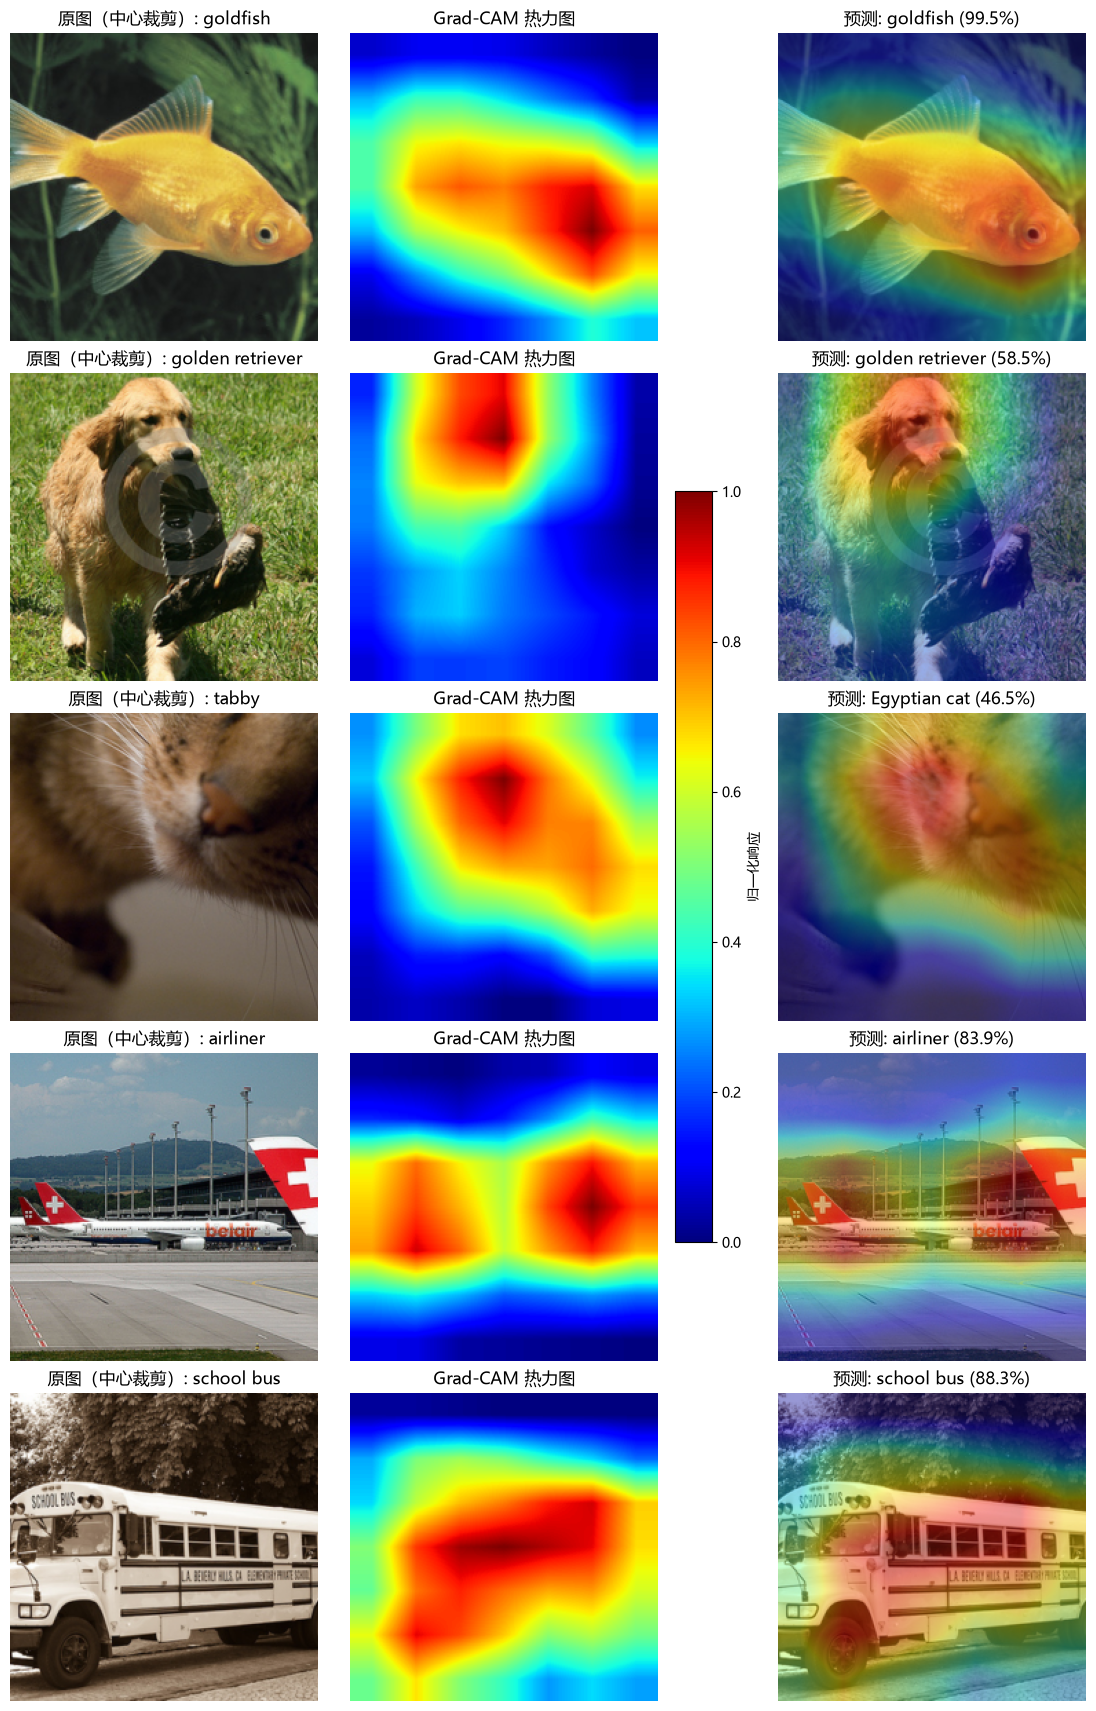

图片和预测结果已保存至： E:\CODE\DeepLearning-exp\exp3\results\exp3A


In [6]:
fig, axes = plt.subplots(len(samples), 3, figsize=(11, 17), constrained_layout=True)

for row, (record, images) in enumerate(zip(records, visualizations)):
    original, heatmap, overlay = images
    axes[row, 0].imshow(original)
    im = axes[row, 1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[row, 2].imshow(overlay)
    axes[row, 0].set_title(f"原图（中心裁剪）: {record['sample_class']}")
    axes[row, 1].set_title("Grad-CAM 热力图")
    axes[row, 2].set_title(
        f"预测: {record['predicted_class']} ({record['probability']:.1%})")
    for ax in axes[row]:
        ax.axis("off")

fig.colorbar(im, ax=axes[:, 1].tolist(), shrink=0.45, label="归一化响应")
fig.savefig(RESULT_DIR / "gradcam_all.png", dpi=200, bbox_inches="tight")
plt.show()

# 分别保存每个类别的三联图，便于插入实验报告
for record, images, (_, filename) in zip(records, visualizations, samples):
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), constrained_layout=True)
    titles = [f"原图: {record['sample_class']}", "Grad-CAM 热力图",
              f"叠加图: {record['predicted_class']} ({record['probability']:.1%})"]
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap="jet", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")
    fig.savefig(RESULT_DIR / f"{Path(filename).stem}_gradcam.png",
                dpi=200, bbox_inches="tight")
    plt.close(fig)

print("图片和预测结果已保存至：", RESULT_DIR)

## 参考资料

[Grad-CAM 原论文](https://arxiv.org/abs/1610.02391)；[Torchvision ResNet-18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)。

结果分析时结合实际图像，观察响应主要落在目标主体、局部结构还是背景，并说明分类是否正确。最后一层特征只有 7 × 7，放大后的热力图较粗糙，不能当作精确的目标分割。